# Miami case study

Miami 26 May 2020: product maps, MRMS/IMERG event totals, Storm Events API, LSRs, Atlas 14, highlighted PFDS table.

Cells are the original session code in execution order (exported verbatim; only secrets handling and artifact paths were changed). Each cell starts with a comment giving its original index, conda environment and run status. Exploratory and failed cells are kept, so later cells that rely on their partial state still make sense.


In [ ]:
# Setup: run from the repository root; helper modules live in prod/
import os, sys
if os.path.basename(os.getcwd())=='notebooks': os.chdir('..')
sys.path.insert(0, 'prod')
os.makedirs('out', exist_ok=True)
from style import apply_figure_style  # stand-in for the figure style used in the session


In [193]:
%%bash
# [orig cell 192 | env: precip | status: ok]
for u in https://mesonet.agron.iastate.edu/archive/data/2020/05/26/stage4/ https://opendap.earthdata.nasa.gov/ https://urs.earthdata.nasa.gov/ https://www.ncei.noaa.gov/data/cmorph-high-resolution-global-precipitation-estimates/access/ https://persiann.eng.uci.edu/CHRSdata/; do echo "$(curl -s -o /dev/null -w '%{http_code} %{time_total}s' --max-time 30 $u) $u"; done

200 0.323435s https://mesonet.agron.iastate.edu/archive/data/2020/05/26/stage4/
200 0.289975s https://opendap.earthdata.nasa.gov/
200 0.456498s https://urs.earthdata.nasa.gov/
200 0.752470s https://www.ncei.noaa.gov/data/cmorph-high-resolution-global-precipitation-estimates/access/
200 0.535822s https://persiann.eng.uci.edu/CHRSdata/


> Original cell 193 ended with status **cancelled** in the session; it is kept for the record.

In [194]:
# [orig cell 193 | env: precip | status: cancelled]
import numpy as np, pandas as pd, requests, gzip, eccodes, h5py, io, os
lat0,lon0=25.788,-80.317
class EDSession(requests.Session):
    def __init__(s,u,p): super().__init__(); s.auth=(u,p)
    def rebuild_auth(s, pr, resp):
        h=pr.headers
        if 'Authorization' in h:
            o=requests.utils.urlparse(resp.request.url).hostname; n=requests.utils.urlparse(pr.url).hostname
            if o!=n and 'urs.earthdata' not in (n or '') and 'urs.earthdata' not in (o or ''): del h['Authorization']
F={}
# Stage IV
r=requests.get('https://mesonet.agron.iastate.edu/archive/data/2020/05/26/stage4/ST4.2020052623.01h.grib',timeout=120)
g=eccodes.codes_new_from_message(r.content); ni=eccodes.codes_get(g,'Ni'); nj=eccodes.codes_get(g,'Nj')
v=eccodes.codes_get_values(g).reshape(nj,ni).astype(np.float32); la=eccodes.codes_get_array(g,'latitudes').reshape(nj,ni); lo=eccodes.codes_get_array(g,'longitudes').reshape(nj,ni); eccodes.codes_release(g)
lo=np.where(lo>180,lo-360,lo); v[(v>9000)|(v<0)]=np.nan
m=(la>25.0)&(la<26.6)&(lo>-81.1)&(lo<-79.5); ii,jj=np.where(m); s=np.s_[ii.min():ii.max()+1,jj.min():jj.max()+1]; F['stage4']=(v[s],la[s],lo[s])
# IMERG two half-hours via cloud OPeNDAP
sess=EDSession(os.environ['EARTHDATA_USER'],os.environ['EARTHDATA_PASS'])
lonI=-179.95+0.1*np.arange(3600); latI=-89.95+0.1*np.arange(1800)
j0,j1=np.searchsorted(lonI,-81.2),np.searchsorted(lonI,-79.4); i0,i1=np.searchsorted(latI,24.9),np.searchsorted(latI,26.7)
acc=[]
for nm in ['3B-HHR.MS.MRG.3IMERG.20200526-S220000-E222959.1320.V07B.HDF5','3B-HHR.MS.MRG.3IMERG.20200526-S223000-E225959.1350.V07B.HDF5']:
    u='https://opendap.earthdata.nasa.gov/collections/C2723754847-GES_DISC/granules/GPM_3IMERGHH.07%3A'+nm+'.dap.nc4'
    r=sess.get(u,params={'dap4.ce':f'/Grid/precipitation[0:1:0][{j0}:1:{j1}][{i0}:1:{i1}]'},timeout=180); r.raise_for_status()
    with h5py.File(io.BytesIO(r.content),'r') as f: x=(f['Grid/precipitation'] if 'Grid' in f else f['precipitation'])[0].astype(np.float32).T
    x[x<0]=np.nan; acc.append(x)
la2,lo2=np.meshgrid(latI[i0:i1+1],lonI[j0:j1+1],indexing='ij'); F['imerg']=((acc[0]+acc[1])/2,la2,lo2)
# CMORPH (file HH holds HH:00 and HH:30)
r=requests.get('https://www.ncei.noaa.gov/data/cmorph-high-resolution-global-precipitation-estimates/access/30min/8km/2020/05/26/CMORPH_V1.0_ADJ_8km-30min_2020052622.nc',timeout=300)
with h5py.File(io.BytesIO(r.content),'r') as f:
    la=f['lat'][:]; lo=f['lon'][:]; ii=np.where((la>24.9)&(la<26.7))[0]; jj=np.where((lo>360-81.2)&(lo<360-79.4))[0]
    raw=f['cmorph'][:,ii[0]:ii[-1]+1,jj[0]:jj[-1]+1].astype(np.float32); sf=float(np.atleast_1d(f['cmorph'].attrs['scale_factor'])[0]); mv=float(np.atleast_1d(f['cmorph'].attrs['missing_value'])[0])
raw[(raw==mv)|(raw<0)]=np.nan; la2,lo2=np.meshgrid(la[ii],lo[jj]-360,indexing='ij'); F['cmorph']=((raw*sf).mean(0),la2,lo2)
# PERSIANN-CCS hour 22 (2020 doy 147)
r=requests.get('https://persiann.eng.uci.edu/CHRSdata/PERSIANN-CCS/hrly/2020/rgccs1h2014722.bin.gz',timeout=300)
a=np.frombuffer(gzip.decompress(r.content),'>i2').reshape(3000,9000)
latP=59.98-0.04*np.arange(3000); lonP=0.02+0.04*np.arange(9000); ii=np.where((latP>24.9)&(latP<26.7))[0]; jj=np.where((lonP>360-81.2)&(lonP<360-79.4))[0]
x=a[ii[0]:ii[-1]+1,jj[0]:jj[-1]+1].astype(np.float32); x[x<0]=np.nan; la2,lo2=np.meshgrid(latP[ii],lonP[jj]-360,indexing='ij'); F['pccs']=(x/100,la2,lo2)
for k,(v,la,lo) in F.items():
    d=(la-lat0)**2+((lo-lon0)*0.9)**2; i,j=np.unravel_index(np.nanargmin(d),d.shape)
    print(k,v.shape,'station pixel',round(float(v[i,j]),1),'max within ~25 km',round(float(np.nanmax(np.where(d<0.23**2,v,np.nan))),1))

Traceback (most recent call last):
  File "<kernel:3>", line 24, in <module>
    r=sess.get(u,params={'dap4.ce':f'/Grid/precipitation[0:1:0][{j0}:1:{j1}][{i0}:1:{i1}]'},timeout=180); r.raise_for_status()
      ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "~/.claude-science/conda/envs/precip/lib/python3.11/site-packages/requests/sessions.py", line 671, in get
    return self.request("GET", url, params=params, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "~/.claude-science/conda/envs/precip/lib/python3.11/site-packages/requests/sessions.py", line 651, in request
    resp = self.send(prep, **send_kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "~/.claude-science/conda/envs/precip/lib/python3.11/site-packages/requests/sessions.py", line 805, in send
    history = [resp for resp in gen]
              ^^^^^^^^^^^^^^^^^^^^^^
  File "~/.claude-science/conda/envs/precip/lib/python3.11/site-pac

In [196]:
%%bash
# [orig cell 195 | env: precip | status: ok]
mkdir -p miami && cd miami
curl -s -o st4.grib -w "st4 %{http_code} %{size_download} %{time_total}s\n" --max-time 120 https://mesonet.agron.iastate.edu/archive/data/2020/05/26/stage4/ST4.2020052623.01h.grib
curl -s -o cm.nc -w "cmorph %{http_code} %{size_download} %{time_total}s\n" --max-time 300 https://www.ncei.noaa.gov/data/cmorph-high-resolution-global-precipitation-estimates/access/30min/8km/2020/05/26/CMORPH_V1.0_ADJ_8km-30min_2020052622.nc
curl -s -o pccs.bin.gz -w "pccs %{http_code} %{size_download} %{time_total}s\n" --max-time 300 https://persiann.eng.uci.edu/CHRSdata/PERSIANN-CCS/hrly/2020/rgccs1h2014722.bin.gz
ls -la

st4 200 1083196 1.571535s
cmorph 200 1639771 1.451341s
pccs 200 1730277 4.191371s
total 12456
drwxr-xr-x@  5 mehdihatamigoloujeh  staff      160 Oct 31 13:32 .
drwxr-xr-x@ 11 mehdihatamigoloujeh  staff      352 Oct 31 13:32 ..
-rw-r--r--@  1 mehdihatamigoloujeh  staff  1639771 Oct 31 13:32 cm.nc
-rw-r--r--@  1 mehdihatamigoloujeh  staff  1730277 Oct 31 13:32 pccs.bin.gz
-rw-r--r--@  1 mehdihatamigoloujeh  staff  1083196 Oct 31 13:32 st4.grib


In [197]:
%%bash
# [orig cell 196 | env: precip | status: ok]
cd miami && python - <<'EOF'
import requests, os, time
class EDSession(requests.Session):
    def __init__(s,u,p): super().__init__(); s.auth=(u,p)
    def rebuild_auth(s, pr, resp):
        h=pr.headers
        if 'Authorization' in h:
            o=requests.utils.urlparse(resp.request.url).hostname; n=requests.utils.urlparse(pr.url).hostname
            if o!=n and 'urs.earthdata' not in (n or '') and 'urs.earthdata' not in (o or ''): del h['Authorization']
s=EDSession(os.environ['EARTHDATA_USER'],os.environ['EARTHDATA_PASS'])
for k,nm in enumerate(['3B-HHR.MS.MRG.3IMERG.20200526-S220000-E222959.1320.V07B.HDF5','3B-HHR.MS.MRG.3IMERG.20200526-S223000-E225959.1350.V07B.HDF5']):
    u='https://opendap.earthdata.nasa.gov/collections/C2723754847-GES_DISC/granules/GPM_3IMERGHH.07%3A'+nm+'.dap.nc4'
    t=time.time()
    try:
        r=s.get(u,params={'dap4.ce':'/Grid/precipitation[0:1:0][989:1:1006][1149:1:1167]'},timeout=(20,60))
        print(k,r.status_code,len(r.content),r.content[:4],round(time.time()-t,1),'s')
        if r.ok: open(f'imerg_{k}.nc4','wb').write(r.content)
    except Exception as e: print(k,'ERR',type(e).__name__,str(e)[:150],round(time.time()-t,1))
EOF

0 200 19923 b'\x89HDF' 2.8 s
1 200 19975 b'\x89HDF' 1.4 s


{'stage4': 54.8, 'pccs': 7.5, 'cmorph': 10.7, 'imerg': 4.6}


~/.claude-science/conda/envs/precip/lib/python3.11/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
~/.claude-science/conda/envs/precip/lib/python3.11/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)

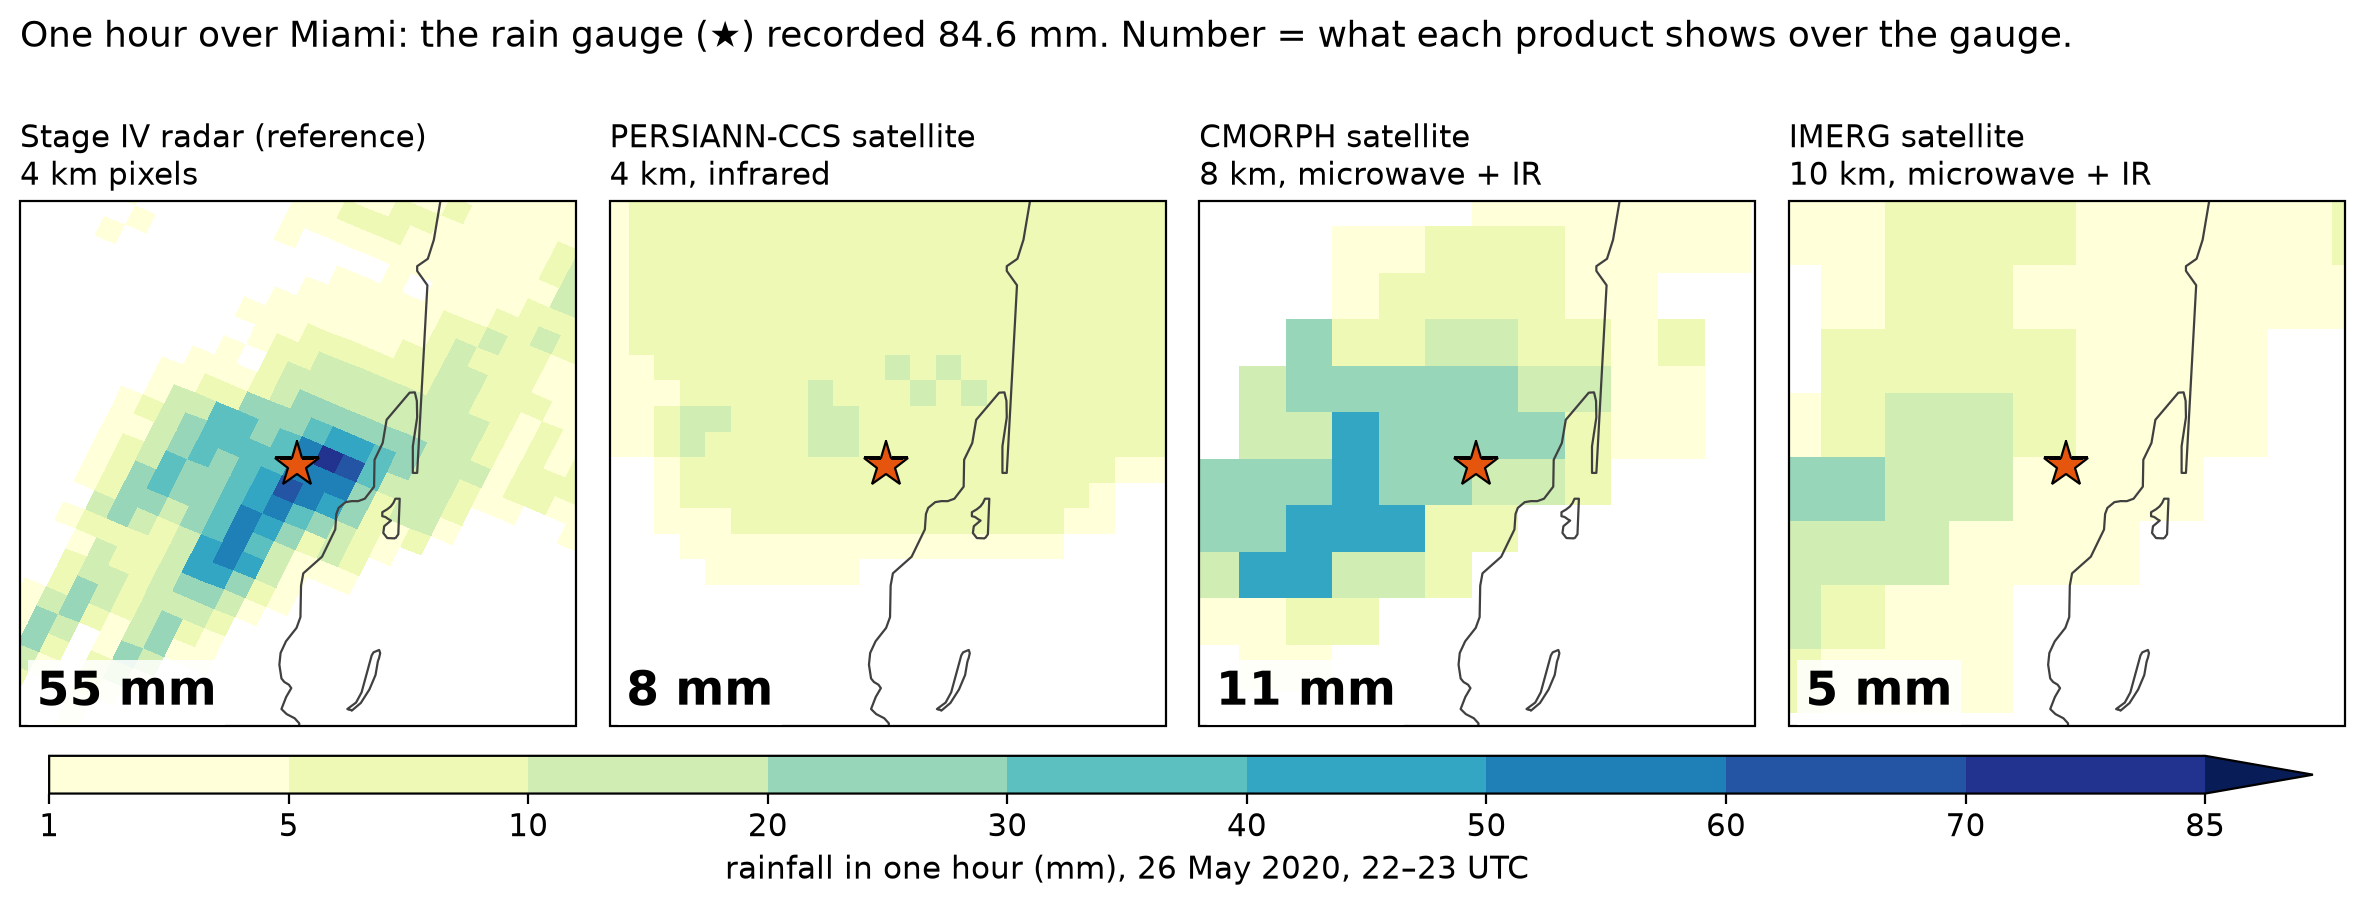

In [198]:
# [orig cell 197 | env: precip | status: ok]
import numpy as np, gzip, eccodes, h5py, os, matplotlib as mpl, matplotlib.pyplot as plt, cartopy, cartopy.crs as ccrs, cartopy.feature as cfeat
cartopy.config['data_dir']=os.path.abspath('cartopy_data'); os.makedirs('cartopy_data',exist_ok=True)
mpl.rcParams.update({'font.size':11,'font.family':'DejaVu Sans'})
lat0,lon0=25.788,-80.317; F={}
b=open('miami/st4.grib','rb').read(); g=eccodes.codes_new_from_message(b); ni=eccodes.codes_get(g,'Ni'); nj=eccodes.codes_get(g,'Nj')
v=eccodes.codes_get_values(g).reshape(nj,ni).astype(np.float32); la=eccodes.codes_get_array(g,'latitudes').reshape(nj,ni); lo=eccodes.codes_get_array(g,'longitudes').reshape(nj,ni); eccodes.codes_release(g)
lo=np.where(lo>180,lo-360,lo); v[(v>9000)|(v<0)]=np.nan; ii,jj=np.where((la>25.0)&(la<26.6)&(lo>-81.1)&(lo<-79.5)); s=np.s_[ii.min():ii.max()+1,jj.min():jj.max()+1]; F['stage4']=(v[s],la[s],lo[s])
a=np.frombuffer(gzip.decompress(open('miami/pccs.bin.gz','rb').read()),'>i2').reshape(3000,9000)
latP=59.98-0.04*np.arange(3000); lonP=0.02+0.04*np.arange(9000); ii=np.where((latP>24.9)&(latP<26.7))[0]; jj=np.where((lonP>360-81.2)&(lonP<360-79.4))[0]
x=a[ii[0]:ii[-1]+1,jj[0]:jj[-1]+1].astype(np.float32); x[x<0]=np.nan; F['pccs']=(x/100,*np.meshgrid(latP[ii],lonP[jj]-360,indexing='ij'))
with h5py.File('miami/cm.nc','r') as f:
    la=f['lat'][:]; lo=f['lon'][:]; ii=np.where((la>24.9)&(la<26.7))[0]; jj=np.where((lo>360-81.2)&(lo<360-79.4))[0]
    raw=f['cmorph'][:,ii[0]:ii[-1]+1,jj[0]:jj[-1]+1].astype(np.float32); sf=float(np.atleast_1d(f['cmorph'].attrs['scale_factor'])[0]); mv=float(np.atleast_1d(f['cmorph'].attrs['missing_value'])[0])
raw[(raw==mv)|(raw<0)]=np.nan; F['cmorph']=((raw*sf).mean(0),*np.meshgrid(la[ii],lo[jj]-360,indexing='ij'))
acc=[]
for k in (0,1):
    with h5py.File(f'miami/imerg_{k}.nc4','r') as f: xx=(f['Grid/precipitation'] if 'Grid' in f else f['precipitation'])[0].astype(np.float32).T
    xx[xx<0]=np.nan; acc.append(xx)
lonI=-179.95+0.1*np.arange(989,1007); latI=-89.95+0.1*np.arange(1149,1168); F['imerg']=((acc[0]+acc[1])/2,*np.meshgrid(latI,lonI,indexing='ij'))
vals={}
for k,(v,la,lo) in F.items():
    d=(la-lat0)**2+((lo-lon0)*0.9)**2; i,j=np.unravel_index(np.nanargmin(d),d.shape); vals[k]=float(v[i,j])
print({k:round(v,1) for k,v in vals.items()})
ext=[-80.75,-79.88,25.38,26.2]
cmap=mpl.colormaps['YlGnBu'].copy(); cmap.set_under('white'); norm=mpl.colors.BoundaryNorm([1,5,10,20,30,40,50,60,70,85],cmap.N,extend='max')
panels=[('stage4','Stage IV radar (reference)\n4 km pixels'),('pccs','PERSIANN-CCS satellite\n4 km, infrared'),('cmorph','CMORPH satellite\n8 km, microwave + IR'),('imerg','IMERG satellite\n10 km, microwave + IR')]
fig,axs=plt.subplots(1,4,figsize=(15,4.9),subplot_kw=dict(projection=ccrs.PlateCarree()),gridspec_kw=dict(wspace=0.06))
for ax,(k,ttl) in zip(axs,panels):
    v,la,lo=F[k]
    im=ax.pcolormesh(lo,la,v,cmap=cmap,norm=norm,shading='nearest' if k!='stage4' else 'auto',transform=ccrs.PlateCarree())
    ax.add_feature(cfeat.COASTLINE.with_scale('10m'),lw=0.8,edgecolor='0.25'); ax.set_extent(ext,crs=ccrs.PlateCarree())
    ax.plot(lon0,lat0,marker='*',ms=17,mfc='#e6550d',mec='k',mew=0.8,transform=ccrs.PlateCarree(),zorder=5)
    ax.set_title(ttl,loc='left',fontsize=11)
    ax.text(0.03,0.04,f'{vals[k]:.0f} mm',transform=ax.transAxes,fontsize=17,fontweight='bold',bbox=dict(facecolor='white',edgecolor='none',alpha=0.85,pad=3))
cb=fig.colorbar(im,ax=axs,orientation='horizontal',fraction=0.05,pad=0.04,aspect=60,ticks=[1,5,10,20,30,40,50,60,70,85]); cb.set_label('rainfall in one hour (mm), 26 May 2020, 22–23 UTC',fontsize=11)
fig.suptitle('One hour over Miami: the rain gauge (★) recorded 84.6 mm. Number = what each product shows over the gauge.',x=0.125,ha='left',y=0.9,fontsize=13)
fig.savefig('sat_fig1_miami.png',dpi=200,bbox_inches='tight')

In [201]:
# [orig cell 200 | env: python | status: ok]
import requests, re, io, pandas as pd
base='https://www.ncei.noaa.gov/pub/data/swdi/stormevents/csvfiles/'
lst=requests.get(base,timeout=60).text
fn=sorted(set(re.findall(r'StormEvents_details-ftp_v1\.0_d2020_c\d+\.csv\.gz',lst)))[-1]; print(fn)
d=pd.read_csv(io.BytesIO(requests.get(base+fn,timeout=300).content),compression='gzip',low_memory=False)
m=d[(d.STATE=='FLORIDA')&(d.BEGIN_YEARMONTH==202005)&(d.BEGIN_DAY.between(25,27))&(d.EVENT_TYPE.str.contains('Flood|Heavy Rain',case=False))]
cols=['BEGIN_DAY','BEGIN_TIME','END_TIME','EVENT_TYPE','CZ_NAME','BEGIN_LOCATION','DAMAGE_PROPERTY','INJURIES_DIRECT','DEATHS_DIRECT','FLOOD_CAUSE','EVENT_ID','EPISODE_ID']
print(m[cols].to_string(index=False))
m[cols+['EVENT_NARRATIVE','EPISODE_NARRATIVE','BEGIN_LAT','BEGIN_LON']].to_csv('miami_storm_events_2020-05.csv',index=False)

StormEvents_details-ftp_v1.0_d2020_c20260323.csv.gz
 BEGIN_DAY  BEGIN_TIME  END_TIME  EVENT_TYPE    CZ_NAME      BEGIN_LOCATION DAMAGE_PROPERTY  INJURIES_DIRECT  DEATHS_DIRECT FLOOD_CAUSE  EVENT_ID  EPISODE_ID
        26        1100      1100       Flood  ST. JOHNS            MOULTRIE           0.00K                0              0  Heavy Rain    883911      147044
        25        2259      2259  Heavy Rain  ST. JOHNS          MARINELAND           0.00K                0              0         NaN    883912      147044
        25        1800      2300       Flood     MARTIN          JUPITER IS           0.00K                0              0  Heavy Rain    886308      147377
        25        1300      1600       Flood MIAMI-DADE               MIAMI           0.00K                0              0  Heavy Rain    892136      148150
        25        1700      1900       Flood MIAMI-DADE     (MIA)MIAMI INTL           0.00K                0              0  Heavy Rain    892138      148150


In [202]:
# [orig cell 201 | env: python | status: ok]
x=pd.read_csv('miami_storm_events_2020-05.csv'); x=x[(x.CZ_NAME=='MIAMI-DADE')&(x.BEGIN_DAY==26)]
print(x.EPISODE_NARRATIVE.iloc[0][:1500]); print()
for _,r in x.iterrows(): print(r.BEGIN_LOCATION, r.DAMAGE_PROPERTY,'|',str(r.EVENT_NARRATIVE)[:500]); print()

A negatively tilted trough located across the Gulf of Mexico lifted north and dampened as weak high pressure gradually encompassed the region. Low-level troughing across central Florida gradually shifted away to the north as Atlantic ridging nosed in from the east. This allowed for southerly low-level winds to prevail. An abundance of moisture created widespread showers and thunderstorms during the afternoon hours with high rainfall rates.The greatest shower and thunderstorm coverage occurred over the east coast metro areas, with a focus over Miami-Dade County. Unfortunately, this was the area most susceptible to hydrological issues given 48 hour rain totals in the 3 to 9 inch range with isolated higher amounts. Flooding was significant and very slow to recede, lasting up to 48 hours in some parts of northern Miami-Dade County.

SWEET WATER 0.00K | Various reports from members of the public. Cars stalling out at the intersection of NW 87th Ave and NW 33rd St. Also, NW 84th Ave flooded 

In [203]:
# [orig cell 202 | env: python | status: ok]
h=pd.read_csv('out/events_ge20_hours.csv',parse_dates=['hour_start_utc'])
mia=h[(h.STATION=='USW00012839')&(h.hour_start_utc.dt.date.astype(str).isin(['2020-05-25','2020-05-26','2020-05-27']))]
print(mia[['hour_start_utc','precip_mm_h','prev_hour_mm','next_hour_mm']].to_string(index=False))

     hour_start_utc  precip_mm_h  prev_hour_mm  next_hour_mm
2020-05-25 20:00:00         26.9           1.3           9.7
2020-05-26 21:00:00         78.5           3.3          84.6
2020-05-26 22:00:00         84.6          78.5           5.8


In [204]:
# [orig cell 203 | env: python | status: ok]
u='https://hdsc.nws.noaa.gov/cgi-bin/new/cgi_readH5.py'
r=requests.get(u,params=dict(lat=25.788,lon=-80.317,type='pf',data='depth',units='english',series='pds'),timeout=60)
print(r.status_code,len(r.text)); txt=r.text
open('atlas14_mia.txt','w').write(txt)
q=re.search(r"quantiles = (\[\[.*?\]\]);",txt,re.S)
import ast
Q=ast.literal_eval(q.group(1)) if q else None
durs=['5-min','10-min','15-min','30-min','60-min','2-hr','3-hr','6-hr','12-hr','24-hr','2-day','3-day','4-day','7-day','10-day','20-day','30-day','45-day','60-day']
rps=[1,2,5,10,25,50,100,200,500,1000]
T=pd.DataFrame([[float(v) for v in row] for row in Q],index=durs[:len(Q)],columns=rps)
print(T.loc[['60-min','2-hr','3-hr','24-hr']])
print(re.findall(r"(region|volume|version)\s*=\s*'([^']*)'",txt)[:5])

200 5123
        1     2     5     10     25     50     100    200    500   1000
60-min  2.09  2.39  2.92  3.39   4.07   4.63   5.22   5.84   6.71   7.4
2-hr    2.60  2.97  3.64  4.25   5.17   5.95   6.78   7.68   8.97  10.0
3-hr    2.89  3.29  4.06  4.78   5.92   6.90   7.98   9.16  10.90  12.3
24-hr   4.64  5.50  7.09  8.57  10.80  12.80  14.90  17.20  20.50  23.2
[('region', 'Southeastern States'), ('volume', '9'), ('version', '2')]


In [205]:
# [orig cell 204 | env: python | status: ok]
ev=pd.read_csv('miami_storm_events_2020-05.csv'); ev=ev[ev.CZ_NAME=='MIAMI-DADE']
ev.to_csv('miami_storm_events_2020-05.csv',index=False)
T.index.name='duration'; T.columns=[f'{c}-yr (in)' for c in T.columns]; T.to_csv('atlas14_miami_intl_pds.csv')
summ=pd.DataFrame([
 dict(metric='Gauge 1-hour total (22–23 UTC)',mm=84.6,inches=round(84.6/25.4,2),atlas14_context='≈10-yr (10-yr 60-min = 3.39 in)'),
 dict(metric='Gauge 2-hour total (21–23 UTC)',mm=163.1,inches=round(163.1/25.4,2),atlas14_context='between 50-yr (5.95 in) and 100-yr (6.78 in)'),
 dict(metric='Stage IV over gauge, 22–23 UTC',mm=54.8,inches=round(54.8/25.4,2),atlas14_context='≈1-yr (1-yr 60-min = 2.09 in)'),
 dict(metric='CMORPH over gauge, 22–23 UTC',mm=10.7,inches=round(10.7/25.4,2),atlas14_context='far below 1-yr'),
 dict(metric='PERSIANN-CCS over gauge, 22–23 UTC',mm=7.5,inches=round(7.5/25.4,2),atlas14_context='far below 1-yr'),
 dict(metric='IMERG over gauge, 22–23 UTC',mm=4.6,inches=round(4.6/25.4,2),atlas14_context='far below 1-yr')])
summ.to_csv('miami_2020-05-26_rain_vs_atlas14.csv',index=False); print(summ.to_string(index=False))
A=lambda v:'{{!artifact:'+v+'}}'
art=open('linkedin_article_satellites.md').read() if os.path.exists('linkedin_article_satellites.md') else None
print(art is not None)

                            metric    mm  inches                              atlas14_context
    Gauge 1-hour total (22–23 UTC)  84.6    3.33              ≈10-yr (10-yr 60-min = 3.39 in)
    Gauge 2-hour total (21–23 UTC) 163.1    6.42 between 50-yr (5.95 in) and 100-yr (6.78 in)
    Stage IV over gauge, 22–23 UTC  54.8    2.16                ≈1-yr (1-yr 60-min = 2.09 in)
      CMORPH over gauge, 22–23 UTC  10.7    0.42                               far below 1-yr
PERSIANN-CCS over gauge, 22–23 UTC   7.5    0.30                               far below 1-yr
       IMERG over gauge, 22–23 UTC   4.6    0.18                               far below 1-yr
True


In [207]:
# [orig cell 206 | env: python | status: ok]
r=requests.get('https://mesonet.agron.iastate.edu/geojson/lsr.php',params={'sts':'202005261600','ets':'202005271200','wfos':'MFL'},timeout=60)
print(r.status_code)
L=pd.json_normalize(r.json()['features'])
L.columns=[c.replace('properties.','') for c in L.columns]
L['lon']=L['geometry.coordinates'].str[0]; L['lat']=L['geometry.coordinates'].str[1]
print(len(L)); print(L.typetext.value_counts().to_dict())
k=L[L.county.str.upper().str.contains('MIAMI|DADE',na=False)|L.lat.between(25.3,26.2)]
print(k[['valid','typetext','magnitude','unit','city','county','lat','lon','remark']].to_string(max_colwidth=70))
k.to_csv('miami_lsr_2020-05-26.csv',index=False)

200
13
{'FLASH FLOOD': 11, 'FLOOD': 1, 'HEAVY RAIN': 1}
                   valid     typetext magnitude  unit                     city      county    lat    lon                                                                 remark
0   2020-05-27T00:45:00Z        FLOOD            None              3 SSE DORAL  MIAMI-DADE  25.80 -80.34  PUBLIC REPORTED ONGOING FLOODING ON NW 87TH AVE BETWEEN NW 36TH ST...
1   2020-05-26T21:52:00Z  FLASH FLOOD            None              3 SSE DORAL  MIAMI-DADE  25.80 -80.34  CARS STALLING OUT AT THE INTERSECTION OF NW 87TH AVE AND NW 33TH S...
2   2020-05-26T22:05:00Z  FLASH FLOOD            None             MIAMI SHORES  MIAMI-DADE  25.86 -80.19  CHANNEL 7 SHOWED VIDEO OF WATER UP TO DOORWAYS AND POSSIBLY ENTERI...
3   2020-05-27T00:00:00Z  FLASH FLOOD            None          1 N MIAMI BEACH  MIAMI-DADE  25.83 -80.13  DELAYED REPORT: NATIONAL WEATHER SERVICE METEOROLOGISTS WITNESSED ...
4   2020-05-26T22:40:00Z  FLASH FLOOD            None        2 W

In [208]:
%%bash
# [orig cell 207 | env: precip | status: ok]
mkdir -p miami/mrms miami/imerg && cd miami && python - <<'EOF'
import requests, pandas as pd, os, concurrent.futures as cf
class EDSession(requests.Session):
    def __init__(s,u,p): super().__init__(); s.auth=(u,p)
    def rebuild_auth(s, pr, resp):
        h=pr.headers
        if 'Authorization' in h:
            o=requests.utils.urlparse(resp.request.url).hostname; n=requests.utils.urlparse(pr.url).hostname
            if o!=n and 'urs.earthdata' not in (n or '') and 'urs.earthdata' not in (o or ''): del h['Authorization']
ends=pd.date_range('2020-05-26 20:00','2020-05-27 03:00',freq='h')   # hour-ending stamps -> 19–03 UTC
def mr(t):
    u=f'https://mtarchive.geol.iastate.edu/{t:%Y/%m/%d}/mrms/ncep/GaugeCorr_QPE_01H/GaugeCorr_QPE_01H_00.00_{t:%Y%m%d-%H}0000.grib2.gz'
    r=requests.get(u,timeout=(20,120)); 
    if r.ok: open(f'mrms/{t:%Y%m%d%H}.grib2.gz','wb').write(r.content)
    return t,r.status_code
with cf.ThreadPoolExecutor(4) as ex: print([s for _,s in ex.map(mr,ends)])
s=EDSession(os.environ['EARTHDATA_USER'],os.environ['EARTHDATA_PASS'])
starts=pd.date_range('2020-05-26 19:00','2020-05-27 02:30',freq='30min')
def im(t):
    e=t+pd.Timedelta(minutes=29,seconds=59)
    nm=f"3B-HHR.MS.MRG.3IMERG.{t:%Y%m%d}-S{t:%H%M%S}-E{e:%H%M%S}.{t.hour*60+t.minute:04d}.V07B.HDF5"
    u='https://opendap.earthdata.nasa.gov/collections/C2723754847-GES_DISC/granules/GPM_3IMERGHH.07%3A'+nm+'.dap.nc4'
    for a in range(3):
        try:
            r=s.get(u,params={'dap4.ce':'/Grid/precipitation[0:1:0][989:1:1006][1149:1:1167]'},timeout=(20,60))
            if r.ok: open(f'imerg/{t:%Y%m%d%H%M}.nc4','wb').write(r.content); return r.status_code
        except Exception as ex_: pass
    return 'fail'
print([im(t) for t in starts])
EOF
ls mrms | wc -l; ls imerg | wc -l

[200, 200, 200, 200, 200, 200, 200, 200]
[200, 200, 200, 200, 200, 200, 200, 200, 200, 200, 200, 200, 200, 200, 200, 200]
       8
      16


In [209]:
# [orig cell 208 | env: precip | status: ok]
import glob, pandas as pd
tot=None
for f in sorted(glob.glob('miami/mrms/*.grib2.gz')):
    b=gzip.decompress(open(f,'rb').read()); g=eccodes.codes_new_from_message(b)
    v=eccodes.codes_get_values(g).reshape(3500,7000).astype(np.float32); eccodes.codes_release(g)
    latM=54.995-0.01*np.arange(3500); lonM=-129.995+0.01*np.arange(7000)
    ii=np.where((latM>25.3)&(latM<26.3))[0]; jj=np.where((lonM>-80.9)&(lonM<-79.9))[0]
    s=v[ii[0]:ii[-1]+1,jj[0]:jj[-1]+1]; s[(s<0)|(s>9000)]=np.nan
    tot=s if tot is None else tot+s
laM,loM=np.meshgrid(latM[ii],lonM[jj],indexing='ij')
imt=None
for f in sorted(glob.glob('miami/imerg/*.nc4')):
    with h5py.File(f,'r') as h: xx=(h['Grid/precipitation'] if 'Grid' in h else h['precipitation'])[0].astype(np.float32).T
    xx[xx<0]=np.nan; xx=xx*0.5; imt=xx if imt is None else imt+xx     # mm/h * 0.5 h
laI,loI=np.meshgrid(-89.95+0.1*np.arange(1149,1168),-179.95+0.1*np.arange(989,1007),indexing='ij')
def at(v,la,lo):
    d=(la-lat0)**2+((lo-lon0)*0.9)**2; i,j=np.unravel_index(np.nanargmin(d),d.shape); return float(v[i,j])
print('event total 19–03 UTC at MIA: MRMS',round(at(tot,laM,loM),1),'IMERG',round(at(imt,laI,loI),1),'| MRMS max in box',round(float(np.nanmax(tot)),1),'IMERG max',round(float(np.nanmax(imt)),1))
L=pd.read_csv('miami_lsr_2020-05-26.csv'); E=pd.read_csv('miami_storm_events_2020-05.csv'); E=E[E.BEGIN_DAY==26]
print(E[['BEGIN_LOCATION','BEGIN_LAT','BEGIN_LON','DAMAGE_PROPERTY']])

event total 19–03 UTC at MIA: MRMS 99.4 IMERG 12.4 | MRMS max in box 122.4 IMERG max 48.3
        BEGIN_LOCATION  BEGIN_LAT  BEGIN_LON DAMAGE_PROPERTY
3          SWEET WATER    25.7968   -80.3415           0.00K
4             PINEWOOD    25.8379   -80.2464          50.00K
5  (OPF)OPA LOCKA ARPT    25.8946   -80.2520          10.00K
6        NORTH BAY VLG    25.8283   -80.1324           0.00K


In [210]:
# [orig cell 209 | env: precip | status: ok]
ext=[-80.52,-80.08,25.62,25.98]
cmap=mpl.colormaps['YlGnBu'].copy(); cmap.set_under('white')
bounds=[2,10,20,40,60,80,100,120,150]; norm=mpl.colors.BoundaryNorm(bounds,cmap.N,extend='max')
fig,axs=plt.subplots(1,2,figsize=(14,6.6),subplot_kw=dict(projection=ccrs.PlateCarree()),gridspec_kw=dict(wspace=0.05))
pan=[(tot,laM,loM,'auto','Radar (MRMS, 1 km): what fell'),(imt,laI,loI,'nearest','Satellite (IMERG, 10 km): what was seen from orbit')]
for ax,(v,la,lo,sh,ttl) in zip(axs,pan):
    im=ax.pcolormesh(lo,la,v,cmap=cmap,norm=norm,shading=sh,transform=ccrs.PlateCarree())
    ax.add_feature(cfeat.COASTLINE.with_scale('10m'),lw=0.9,edgecolor='0.25'); ax.set_extent(ext,crs=ccrs.PlateCarree())
    ff=L[L.typetext.str.contains('FLOOD')]
    ax.scatter(ff.lon,ff.lat,marker='v',s=95,c='#d7301f',edgecolor='k',lw=0.7,transform=ccrs.PlateCarree(),zorder=5,label='flash-flood / flood report (NWS)')
    ax.scatter(E.BEGIN_LON,E.BEGIN_LAT,marker='s',s=80,facecolor='none',edgecolor='#d7301f',lw=2,transform=ccrs.PlateCarree(),zorder=5,label='flooded buildings / damage (NOAA Storm Events)')
    ax.plot(lon0,lat0,marker='*',ms=19,mfc='#fdae61',mec='k',mew=0.8,transform=ccrs.PlateCarree(),zorder=6,label='Miami Intl gauge: 163 mm in 2 h')
    ax.set_title(ttl,loc='left',fontsize=12)
axs[0].text(-80.235,25.885,'Opa-locka:\napartments with\n≥18 in of water',fontsize=8.5,transform=ccrs.PlateCarree(),ha='left',bbox=dict(facecolor='white',alpha=0.8,edgecolor='none',pad=1.5))
axs[0].text(-80.300,25.848,'I-95 ramp waist-deep;\n48 structures flooded',fontsize=8.5,transform=ccrs.PlateCarree(),ha='right',bbox=dict(facecolor='white',alpha=0.8,edgecolor='none',pad=1.5))
h_,l_=axs[0].get_legend_handles_labels()
fig.legend(h_,l_,loc='lower center',ncol=3,frameon=False,fontsize=10,bbox_to_anchor=(0.5,0.02))
cb=fig.colorbar(im,ax=axs,orientation='horizontal',fraction=0.04,pad=0.09,aspect=60,ticks=bounds); cb.set_label('rainfall total, 3–11 pm local, 26 May 2020 (mm)',fontsize=11)
fig.suptitle('Miami, 26 May 2020: flood reports sit under the radar-observed downpour; the satellite saw a light shower',x=0.125,ha='left',y=0.96,fontsize=13)
fig.savefig('sat_fig4_flood_map.png',dpi=200,bbox_inches='tight')

In [211]:
# [orig cell 210 | env: precip | status: ok]
fig,axs=plt.subplots(1,2,figsize=(14,6.9),subplot_kw=dict(projection=ccrs.PlateCarree()),gridspec_kw=dict(wspace=0.05))
for ax,(v,la,lo,sh,ttl) in zip(axs,pan):
    im=ax.pcolormesh(lo,la,v,cmap=cmap,norm=norm,shading=sh,transform=ccrs.PlateCarree())
    ax.add_feature(cfeat.COASTLINE.with_scale('10m'),lw=0.9,edgecolor='0.25'); ax.set_extent(ext,crs=ccrs.PlateCarree())
    ff=L[L.typetext.str.contains('FLOOD')]
    ax.scatter(ff.lon,ff.lat,marker='v',s=95,c='#d7301f',edgecolor='k',lw=0.7,transform=ccrs.PlateCarree(),zorder=5,label='flash-flood / flood report (NWS)')
    ax.scatter(E.BEGIN_LON,E.BEGIN_LAT,marker='s',s=80,facecolor='none',edgecolor='#d7301f',lw=2,transform=ccrs.PlateCarree(),zorder=5,label='flooded buildings (NOAA Storm Events)')
    ax.plot(lon0,lat0,marker='*',ms=19,mfc='#fdae61',mec='k',mew=0.8,ls='none',transform=ccrs.PlateCarree(),zorder=6,label='Miami Intl gauge')
    ax.set_title(ttl,loc='left',fontsize=12)
    ax.annotate(f'{at(v,la,lo):.0f} mm here',xy=(lon0,lat0),xytext=(lon0-0.02,lat0-0.055),xycoords=ccrs.PlateCarree()._as_mpl_transform(ax),textcoords=ccrs.PlateCarree()._as_mpl_transform(ax),
                fontsize=11,fontweight='bold',ha='center',bbox=dict(facecolor='white',alpha=0.85,edgecolor='none',pad=2),arrowprops=dict(arrowstyle='-',color='k',lw=0.8))
tr=ccrs.PlateCarree()._as_mpl_transform(axs[0]); kw=dict(fontsize=8.5,bbox=dict(facecolor='white',alpha=0.85,edgecolor='none',pad=1.5),arrowprops=dict(arrowstyle='-',color='0.2',lw=0.8),xycoords=tr,textcoords=tr)
axs[0].annotate('Opa-locka: apartments\nwith ≥18 in of water',xy=(-80.2520,25.8946),xytext=(-80.40,25.95),ha='center',**kw)
axs[0].annotate('Trailer park: up to 48\nstructures flooded;\nI-95 ramp waist-deep',xy=(-80.2464,25.8379),xytext=(-80.43,25.885),ha='center',**kw)
axs[0].annotate('Gauge: 163 mm\nin 2 hours',xy=(lon0,lat0),xytext=(-80.43,25.74),ha='center',**kw)
h_,l_=axs[0].get_legend_handles_labels()
fig.legend(h_,l_,loc='upper left',ncol=3,frameon=False,fontsize=10,bbox_to_anchor=(0.12,0.955))
cb=fig.colorbar(im,ax=axs,orientation='horizontal',fraction=0.04,pad=0.04,aspect=60,ticks=bounds); cb.set_label('rainfall total, 3–11 pm local time, 26 May 2020 (mm)',fontsize=11)
fig.suptitle('Miami, 26 May 2020: radar shows the downpour where floods were reported; the satellite saw much less rain',x=0.125,ha='left',y=1.0,fontsize=13)
fig.savefig('sat_fig4_flood_map.png',dpi=200,bbox_inches='tight')
r=fig.canvas.get_renderer(); tx=[x_ for x_ in fig.findobj(mpl.text.Text) if x_.get_text().strip() and x_.get_visible()]; bb=[x_.get_window_extent(r) for x_ in tx]
print([(tx[i].get_text()[:20],tx[j].get_text()[:20]) for i in range(len(bb)) for j in range(i+1,len(bb)) if bb[i].overlaps(bb[j])])

[('99 mm here', 'Gauge: 163 mm\nin 2 h'), ('Opa-locka: apartment', 'Trailer park: up to ')]


In [212]:
# [orig cell 211 | env: precip | status: ok]
for ax,nm in zip(axs,['Radar','Satellite']):
    for t_ in ax.texts:
        if t_.get_text().endswith('mm here'): t_.set_text(f"{nm}: {t_.get_text().split()[0]} mm\nover all 8 hours")
for t_ in axs[0].texts:
    if t_.get_text().startswith('Gauge'): t_.set_text('Gauge: 163 mm in\njust 2 hours')
fig.legends[0].set_bbox_to_anchor((0.12,0.93))
fig.savefig('sat_fig4_flood_map.png',dpi=200,bbox_inches='tight')

In [213]:
# [orig cell 212 | env: precip | status: ok]
for t_ in axs[0].texts:
    if t_.get_text().startswith('Gauge'): t_.set_position((-80.45,25.69))
    if t_.get_text().startswith('Radar'): t_.set_position((lon0+0.05,lat0-0.075))
for t_ in axs[1].texts:
    if t_.get_text().startswith('Satellite'): t_.set_position((lon0+0.05,lat0-0.075))
fig.legends[0].set_bbox_to_anchor((0.12,0.895)); fig._suptitle.set_y(0.94)
fig.savefig('sat_fig4_flood_map.png',dpi=200,bbox_inches='tight')
r=fig.canvas.get_renderer(); tx=[x_ for x_ in fig.findobj(mpl.text.Text) if x_.get_text().strip() and x_.get_visible()]; bb=[x_.get_window_extent(r) for x_ in tx]
print([(tx[i].get_text()[:20],tx[j].get_text()[:20]) for i in range(len(bb)) for j in range(i+1,len(bb)) if bb[i].overlaps(bb[j])])

[('Radar: 99 mm\nover al', 'Gauge: 163 mm in\njus'), ('Opa-locka: apartment', 'Trailer park: up to ')]


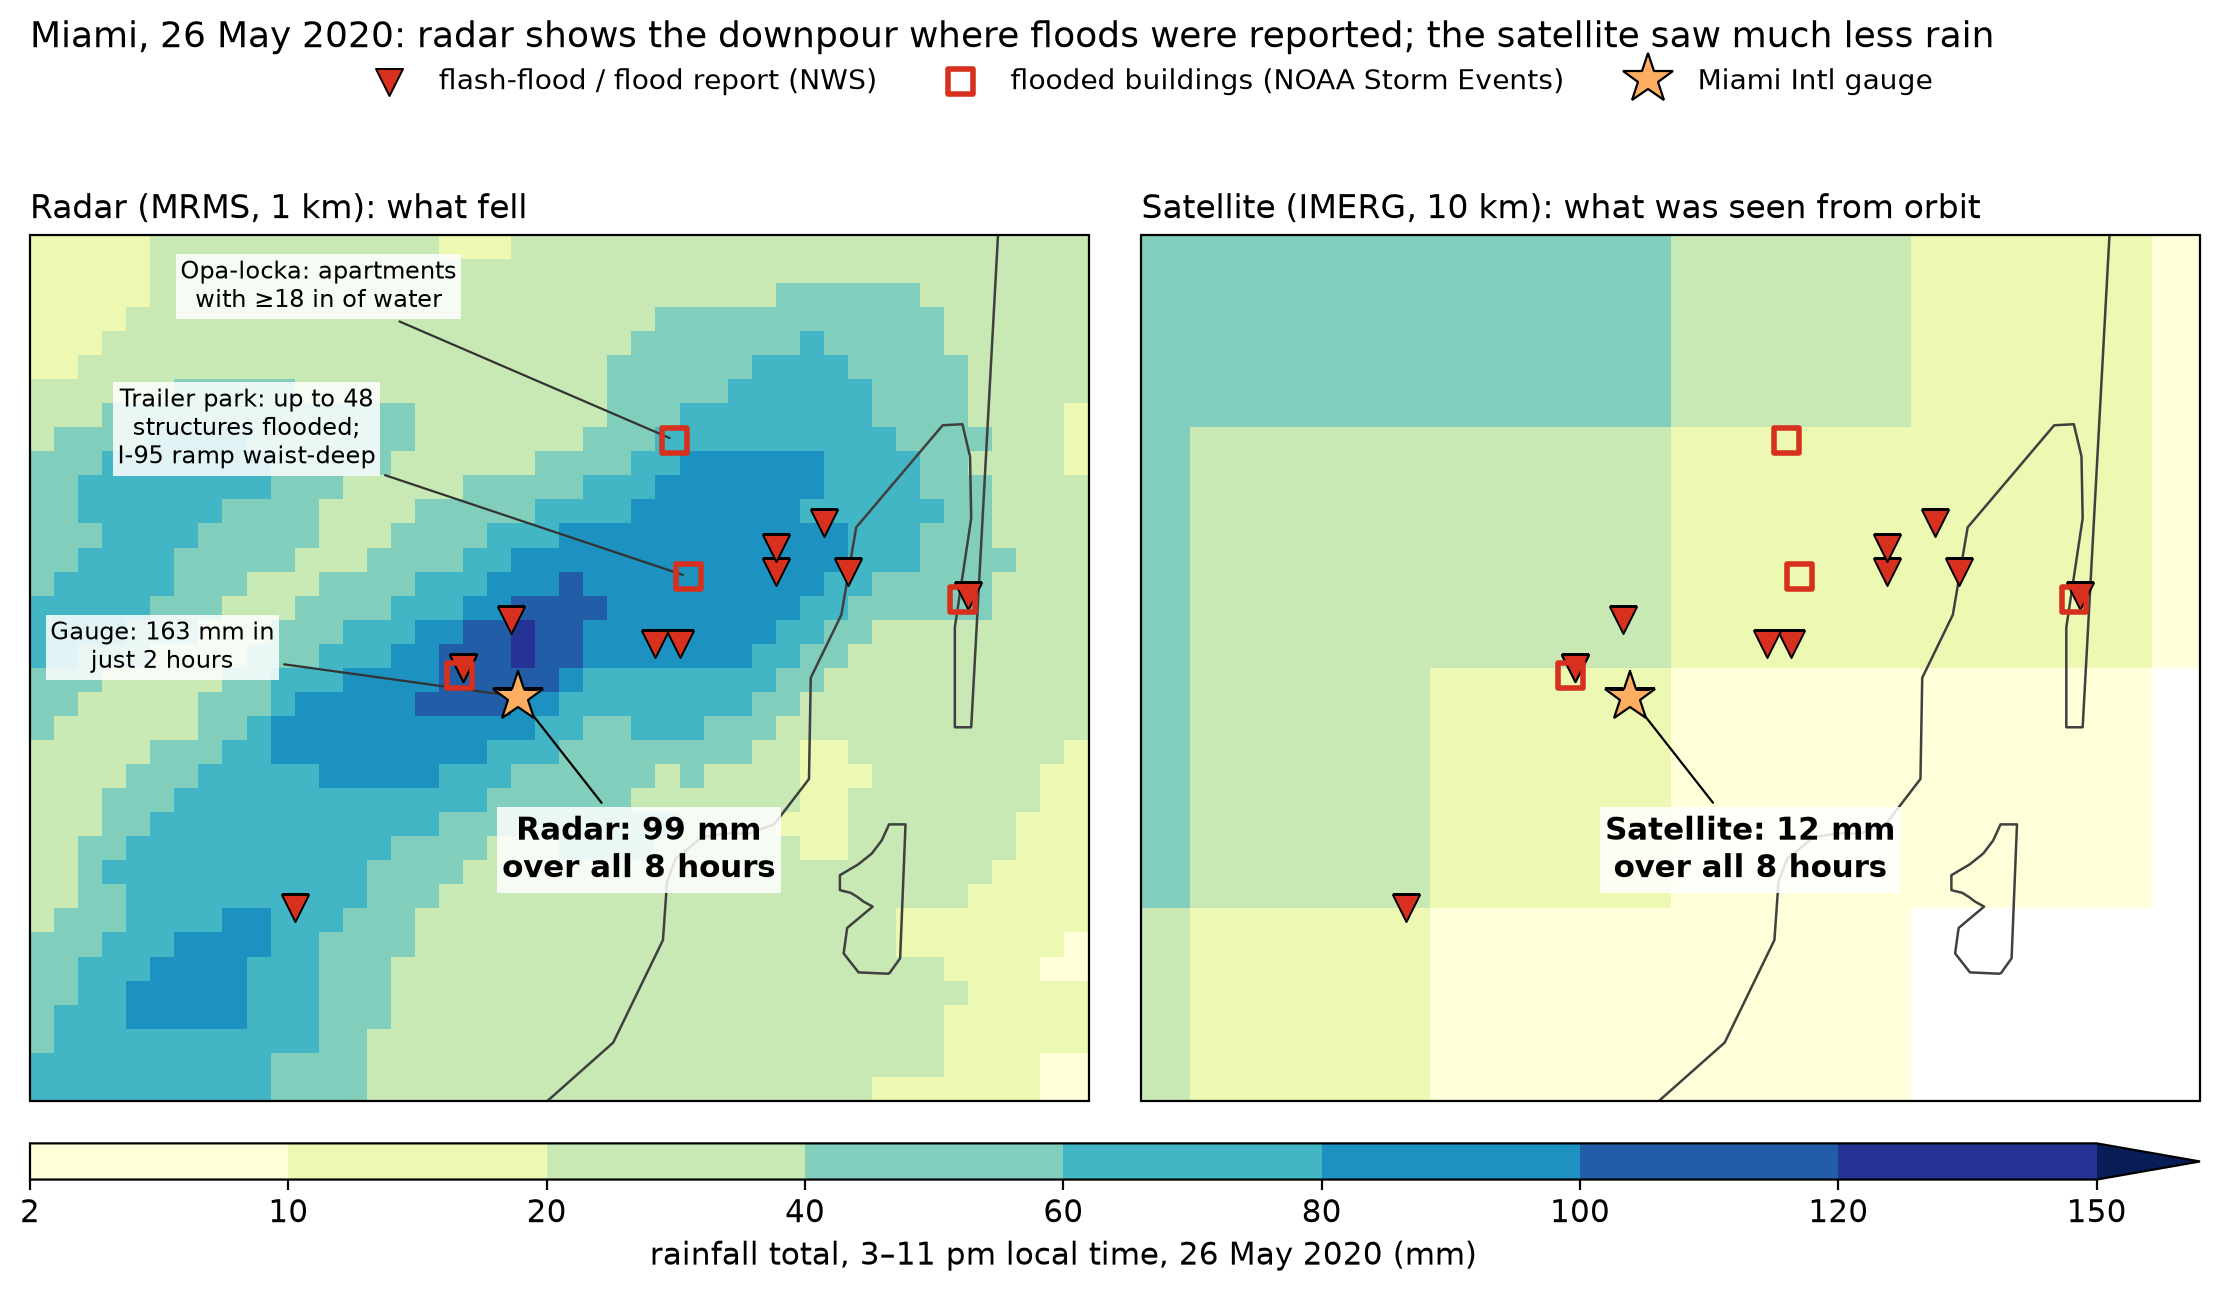

In [214]:
# [orig cell 213 | env: precip | status: ok]
for t_ in axs[0].texts:
    if t_.get_text().startswith('Gauge'): t_.set_position((-80.465,25.80))
fig.legends[0].set_bbox_to_anchor((0.12,0.905)); fig._suptitle.set_y(0.955)
fig.savefig('sat_fig4_flood_map.png',dpi=200,bbox_inches='tight')

In [217]:
%%bash
# [orig cell 216 | env: precip | status: ok]
mkdir -p miami/mrms miami/imerg && cd miami && python - <<'EOF'
import requests, pandas as pd, os, concurrent.futures as cf
class EDSession(requests.Session):
    def __init__(s,u,p): super().__init__(); s.auth=(u,p)
    def rebuild_auth(s, pr, resp):
        h=pr.headers
        if 'Authorization' in h:
            o=requests.utils.urlparse(resp.request.url).hostname; n=requests.utils.urlparse(pr.url).hostname
            if o!=n and 'urs.earthdata' not in (n or '') and 'urs.earthdata' not in (o or ''): del h['Authorization']
def mr(t):
    u=f'https://mtarchive.geol.iastate.edu/{t:%Y/%m/%d}/mrms/ncep/GaugeCorr_QPE_01H/GaugeCorr_QPE_01H_00.00_{t:%Y%m%d-%H}0000.grib2.gz'
    r=requests.get(u,timeout=(20,120))
    if r.ok: open(f'mrms/{t:%Y%m%d%H}.grib2.gz','wb').write(r.content)
    return r.status_code
with cf.ThreadPoolExecutor(4) as ex: print(list(ex.map(mr,pd.date_range('2020-05-26 20:00','2020-05-27 03:00',freq='h'))))
s=EDSession(os.environ['EARTHDATA_USER'],os.environ['EARTHDATA_PASS'])
def im(t):
    e=t+pd.Timedelta(minutes=29,seconds=59)
    nm=f"3B-HHR.MS.MRG.3IMERG.{t:%Y%m%d}-S{t:%H%M%S}-E{e:%H%M%S}.{t.hour*60+t.minute:04d}.V07B.HDF5"
    u='https://opendap.earthdata.nasa.gov/collections/C2723754847-GES_DISC/granules/GPM_3IMERGHH.07%3A'+nm+'.dap.nc4'
    for a in range(3):
        try:
            r=s.get(u,params={'dap4.ce':'/Grid/precipitation[0:1:0][985:1:1010][1145:1:1172]'},timeout=(20,60))
            if r.ok: open(f'imerg/{t:%Y%m%d%H%M}.nc4','wb').write(r.content); return 200
        except Exception: pass
    return 'fail'
print([im(t) for t in pd.date_range('2020-05-26 19:00','2020-05-27 02:30',freq='30min')])
EOF
ls mrms | wc -l; ls imerg | wc -l

[200, 200, 200, 200, 200, 200, 200, 200]
[200, 200, 200, 200, 200, 200, 200, 200, 200, 200, 200, 200, 200, 200, 200, 200]
       8
      16


In [218]:
# [orig cell 217 | env: precip | status: ok]
import numpy as np, glob, gzip, eccodes, h5py, os, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt, cartopy, cartopy.crs as ccrs, cartopy.feature as cfeat
cartopy.config['data_dir']=os.path.abspath('cartopy_data'); os.makedirs('cartopy_data',exist_ok=True)
lat0,lon0=25.788,-80.317
latM=54.995-0.01*np.arange(3500); lonM=-129.995+0.01*np.arange(7000)
ii=np.where((latM>25.4)&(latM<26.2))[0]; jj=np.where((lonM>-80.8)&(lonM<-79.8))[0]; tot=None
for f in sorted(glob.glob('miami/mrms/*.grib2.gz')):
    g=eccodes.codes_new_from_message(gzip.decompress(open(f,'rb').read())); v=eccodes.codes_get_values(g).reshape(3500,7000).astype(np.float32); eccodes.codes_release(g)
    s=v[ii[0]:ii[-1]+1,jj[0]:jj[-1]+1]; s[(s<0)|(s>9000)]=np.nan; tot=s if tot is None else tot+s
laM,loM=np.meshgrid(latM[ii],lonM[jj],indexing='ij')
imt=None
for f in sorted(glob.glob('miami/imerg/*.nc4')):
    with h5py.File(f,'r') as h: x=(h['Grid/precipitation'] if 'Grid' in h else h['precipitation'])[0].astype(np.float32).T
    x[x<0]=np.nan; imt=x*0.5 if imt is None else imt+x*0.5
laI,loI=np.meshgrid(-89.95+0.1*np.arange(1145,1173),-179.95+0.1*np.arange(985,1011),indexing='ij')
def at(v,la,lo):
    d=(la-lat0)**2+((lo-lon0)*0.9)**2; i,j=np.unravel_index(np.nanargmin(d),d.shape); return float(v[i,j])
print('MRMS at gauge',round(at(tot,laM,loM),1),'IMERG at gauge',round(at(imt,laI,loI),1))
L=pd.read_csv('out/miami_lsr_2020-05-26.csv'); ff=L[L.typetext.str.contains('FLOOD')]

bg='#0b1726'
cmap=mpl.colormaps['YlGnBu'].copy(); cmap.set_under((0,0,0,0)); cmap.set_bad((0,0,0,0))
bounds=[2,10,20,40,60,80,100,120,150]; norm=mpl.colors.BoundaryNorm(bounds,cmap.N,extend='max')
ext=[-80.60,-80.02,25.56,26.04]
fig=plt.figure(figsize=(19.2,10.8),dpi=100,facecolor=bg)
fig.text(0.5,0.915,'Satellites see the storm, not the downpour',ha='center',va='center',color='white',fontsize=52,fontweight='bold',family='DejaVu Sans')
fig.text(0.5,0.835,'Miami, 26 May 2020  ·  a rain gauge measured 163 mm in 2 hours and streets and homes flooded',ha='center',va='center',color='#c9d6e3',fontsize=22)
pos=[[0.045,0.10,0.44,0.67],[0.515,0.10,0.44,0.67]]
pan=[(tot,laM,loM,'auto','RADAR','what fell',at(tot,laM,loM)),(imt,laI,loI,'nearest','SATELLITE','what was seen from orbit',at(imt,laI,loI))]
for p,(v,la,lo,sh,big,small,val) in zip(pos,pan):
    ax=fig.add_axes(p,projection=ccrs.PlateCarree()); ax.set_facecolor('#13263b')
    ax.pcolormesh(lo,la,np.ma.masked_less(v,2),cmap=cmap,norm=norm,shading=sh,transform=ccrs.PlateCarree())
    ax.add_feature(cfeat.COASTLINE.with_scale('10m'),lw=1.4,edgecolor='#e8eef5')
    ax.set_extent(ext,crs=ccrs.PlateCarree())
    for sp in ax.spines.values(): sp.set_edgecolor('#3d5670'); sp.set_linewidth(1.5)
    ax.scatter(ff.lon,ff.lat,marker='v',s=150,c='#ff5a36',edgecolor='white',lw=1.0,transform=ccrs.PlateCarree(),zorder=5)
    ax.plot(lon0,lat0,marker='*',ms=30,mfc='#ffd166',mec='k',mew=1.0,transform=ccrs.PlateCarree(),zorder=6)
    ax.text(0.03,0.96,big,transform=ax.transAxes,color='white',fontsize=34,fontweight='bold',va='top',
            bbox=dict(facecolor=bg,alpha=0.75,edgecolor='none',pad=6))
    ax.text(0.03,0.835,small,transform=ax.transAxes,color='#c9d6e3',fontsize=19,va='top',bbox=dict(facecolor=bg,alpha=0.75,edgecolor='none',pad=4))
    ax.text(0.97,0.05,f'{val:.0f} mm',transform=ax.transAxes,color='white',fontsize=44,fontweight='bold',ha='right',va='bottom',
            bbox=dict(facecolor=bg,alpha=0.8,edgecolor='none',pad=6))
    ax.text(0.97,0.19,'over the gauge, 3–11 pm',transform=ax.transAxes,color='#c9d6e3',fontsize=16,ha='right',va='bottom',bbox=dict(facecolor=bg,alpha=0.8,edgecolor='none',pad=3))
fig.text(0.045,0.045,'▼ flood reports (NWS)     ★ Miami Intl rain gauge     shading: rainfall 3–11 pm local, mm',color='#9fb2c6',fontsize=15,va='center')
cax=fig.add_axes([0.62,0.035,0.335,0.02]); cb=fig.colorbar(mpl.cm.ScalarMappable(norm=norm,cmap=cmap),cax=cax,orientation='horizontal',ticks=bounds)
cb.ax.tick_params(colors='#c9d6e3',labelsize=12); cb.outline.set_edgecolor('#3d5670')
fig.savefig('cover_linkedin_1920x1080.png',dpi=100,facecolor=bg)
from PIL import Image; print(Image.open('cover_linkedin_1920x1080.png').size)

MRMS at gauge 99.4 IMERG at gauge 12.4
(1920, 1080)


Matplotlib is building the font cache; this may take a moment.
~/.claude-science/conda/envs/precip/lib/python3.11/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)

In [219]:
# [orig cell 218 | env: precip | status: ok]
cmap=mpl.colormaps['viridis'].copy(); cmap.set_under((0,0,0,0)); cmap.set_bad((0,0,0,0)); norm=mpl.colors.BoundaryNorm(bounds,cmap.N,extend='max')
fig=plt.figure(figsize=(19.2,10.8),dpi=100,facecolor=bg)
fig.text(0.5,0.915,'Satellites see the storm, not the downpour',ha='center',va='center',color='white',fontsize=52,fontweight='bold')
fig.text(0.5,0.835,'Miami, 26 May 2020  ·  a rain gauge measured 163 mm in 2 hours and streets and homes flooded',ha='center',va='center',color='#c9d6e3',fontsize=22)
for p,(v,la,lo,sh,big,small,val) in zip(pos,pan):
    ax=fig.add_axes(p,projection=ccrs.PlateCarree()); ax.set_facecolor('#0f2033')
    ax.pcolormesh(lo,la,np.ma.masked_less(v,2),cmap=cmap,norm=norm,shading=sh,transform=ccrs.PlateCarree())
    ax.add_feature(cfeat.COASTLINE.with_scale('10m'),lw=1.6,edgecolor='white')
    ax.set_extent(ext,crs=ccrs.PlateCarree())
    for sp in ax.spines.values(): sp.set_edgecolor('#3d5670'); sp.set_linewidth(1.5)
    ax.scatter(ff.lon,ff.lat,marker='v',s=160,c='#ff5a36',edgecolor='white',lw=1.0,transform=ccrs.PlateCarree(),zorder=5)
    ax.plot(lon0,lat0,marker='*',ms=32,mfc='#ffffff',mec='k',mew=1.2,transform=ccrs.PlateCarree(),zorder=6)
    ax.text(0.035,0.955,big,transform=ax.transAxes,color='white',fontsize=34,fontweight='bold',va='top',bbox=dict(facecolor=bg,alpha=0.8,edgecolor='none',pad=6))
    ax.text(0.035,0.83,small,transform=ax.transAxes,color='#c9d6e3',fontsize=19,va='top',bbox=dict(facecolor=bg,alpha=0.8,edgecolor='none',pad=4))
    ax.text(0.94,0.07,f'{val:.0f} mm',transform=ax.transAxes,color='white',fontsize=44,fontweight='bold',ha='right',va='bottom',bbox=dict(facecolor=bg,alpha=0.85,edgecolor='none',pad=6))
    ax.text(0.94,0.215,'over the gauge (★), 3–11 pm',transform=ax.transAxes,color='#c9d6e3',fontsize=16,ha='right',va='bottom',bbox=dict(facecolor=bg,alpha=0.85,edgecolor='none',pad=3))
fig.text(0.045,0.045,'▼ flood reports (NWS)     ★ Miami Intl rain gauge     colour: rainfall 3–11 pm local (mm)',color='#9fb2c6',fontsize=15,va='center')
cax=fig.add_axes([0.62,0.035,0.335,0.02]); cb=fig.colorbar(mpl.cm.ScalarMappable(norm=norm,cmap=cmap),cax=cax,orientation='horizontal',ticks=bounds)
cb.ax.tick_params(colors='#c9d6e3',labelsize=12); cb.outline.set_edgecolor('#3d5670')
fig.savefig('cover_linkedin_1920x1080.png',dpi=100,facecolor=bg)

In [227]:
# [orig cell 226 | env: python | status: ok]
import pandas as pd, requests
E=pd.read_csv('out/miami_storm_events_2020-05.csv')
E=E[E.BEGIN_DAY==26][['EVENT_ID','EPISODE_ID','BEGIN_LOCATION','EVENT_TYPE','DAMAGE_PROPERTY']]; print(E.to_string(index=False))
urls={'storm_event':f"https://www.ncdc.noaa.gov/stormevents/eventdetails.jsp?id={E.EVENT_ID.iloc[1]}",
      'pfds_print':'https://hdsc.nws.noaa.gov/pfds/pfds_printpage.html?lat=25.788&lon=-80.317&data=depth&units=english&series=pds',
      'pfds_map':'https://hdsc.nws.noaa.gov/pfds/pfds_map_cont.html?bkmrk=fl'}
for k,u in urls.items():
    try: r=requests.get(u,timeout=30,allow_redirects=True); print(k,r.status_code,r.url[:120],len(r.text))
    except Exception as e: print(k,'ERR',type(e).__name__,str(e)[:120])

 EVENT_ID  EPISODE_ID      BEGIN_LOCATION EVENT_TYPE DAMAGE_PROPERTY
   892248      148171         SWEET WATER      Flood           0.00K
   892252      148171            PINEWOOD      Flood          50.00K
   896928      148171 (OPF)OPA LOCKA ARPT      Flood          10.00K
   896929      148171       NORTH BAY VLG      Flood           0.00K
storm_event ERR ProxyError HTTPSConnectionPool(host='www.ncdc.noaa.gov', port=443): Max retries exceeded with url: /stormevents/eventdetails.jsp?id
pfds_print 200 https://hdsc.nws.noaa.gov/pfds/pfds_printpage.html?lat=25.788&lon=-80.317&data=depth&units=english&series=pds 26543
pfds_map 200 https://hdsc.nws.noaa.gov/pfds/pfds_map_cont.html?bkmrk=fl 126318


In [228]:
# [orig cell 227 | env: python | status: ok]
import re
for eid in E.EVENT_ID:
    u=f"https://www.ncdc.noaa.gov/stormevents/eventdetails.jsp?id={eid}"
    try:
        r=requests.get(u,timeout=60,allow_redirects=True)
        t=re.sub(r'\s+',' ',re.sub('<[^>]+>',' ',r.text))
        print(eid,r.status_code,r.url[:90],'| Miami-Dade' if 'MIAMI-DADE' in t.upper() else '| ?','| 05/26/2020' if '05/26/2020' in t else '', '| ep 148171' if '148171' in t else '')
    except Exception as e: print(eid,'ERR',str(e)[:100])

892248 200 https://www.ncei.noaa.gov/access/storm-events-database/?id=892248 | ?  
892252 200 https://www.ncei.noaa.gov/access/storm-events-database/?id=892252 | ?  
896928 200 https://www.ncei.noaa.gov/access/storm-events-database/?id=896928 | ?  
896929 200 https://www.ncei.noaa.gov/access/storm-events-database/?id=896929 | ?  


In [229]:
# [orig cell 228 | env: python | status: ok]
r=requests.get('https://www.ncei.noaa.gov/access/storm-events-database/?id=892252',timeout=60)
h=r.text; print(len(h)); 
print(re.findall(r'<title>(.*?)</title>',h,re.S))
print(sorted(set(re.findall(r'(?:src|href)="([^"]*(?:\.js|api|event)[^"]*)"',h)))[:20])
i=h.lower().find('eventdetail'); print(h[i-200:i+300] if i>0 else 'no eventdetail string')

1162
['Storm Events Database']
['/access/storm-events-database/assets/index-BDF-ROjl.js', '/access/storm-events-database/assets/index-DicR0wgj.css', '/access/storm-events-database/assets/js/default.js', '/access/storm-events-database/assets/media/favicon.ico', '/access/storm-events-database/logo192.png', 'https://dap.digitalgov.gov/Universal-Federated-Analytics-Min.js?agency=DOC&subagency=NOAA']
no eventdetail string


In [230]:
# [orig cell 229 | env: python | status: ok]
js=requests.get('https://www.ncei.noaa.gov/access/storm-events-database/assets/index-BDF-ROjl.js',timeout=120).text
print(len(js))
for kw in ['eventdetails','event-details','get("id")',"get('id')",'searchParams','/api/','eventId','event_id']:
    for m in list(re.finditer(re.escape(kw),js))[:2]: print(kw,'::',js[max(0,m.start()-120):m.start()+160].replace('\n',' ')); print()

3747828
event-details :: rts.useState(0),O=(Te,Ae)=>{v(Ae)},te=[{year:"1959",value1:"260",value2:"1813",percentage:"14%",note:"Example 1",link:"/event-details/10019292"},{year:"1960-1969",value1:"6139",value2:"25045",percentage:"24%",note:"Example 2",link:"/event-details/10091775"},{year:"1970-1979",valu

event-details :: link:"/event-details/10019292"},{year:"1960-1969",value1:"6139",value2:"25045",percentage:"24%",note:"Example 2",link:"/event-details/10091775"},{year:"1970-1979",value1:"14823",value2:"39089",percentage:"38%",note:"Example 3",link:"/event-details/10048419"},{year:"1980-1989",val

searchParams :: e=[];for(let Ce of x)typeof Ce.route.shouldRevalidate=="function"?me=!0:be.push(Ce.route.id);return me&&be.length>0&&pe.searchParams.set("_routes",be.join(",")),[pe.pathname+pe.search]},[ne,te.v8_trailingSlashAwareDataRequests,D,O,x]);return reactExports.createElement(reactExport

searchParams :: ),Pe.size===0)return[];let nt=singleFetchUrl(D,pe,te.v8_trailingSlashAwareDataRe

In [231]:
# [orig cell 230 | env: python | status: ok]
i=js.find('getDetails=D=>'); print(js[i:i+300])
m=re.search(r'frontendUrl\s*=\s*"([^"]*)"',js) or re.search(r'frontendUrl:"([^"]*)"',js); print('frontendUrl', m.group(1) if m else None)
m2=re.search(r'baseURL:\s*"?([^",}]*)',js); print('baseURL', m2.group(1) if m2 else None)

getDetails=D=>{const x=`/api/${D.detailType}-details`;return postRequest(x,D)},getLatex=D=>postRequest("/api/pdf-latex",D),getCsvResults=D=>postRequest("/api/csv-results",D),getCertify=D=>postRequest("/api/pdf-certify",D),getMinMaxDates=()=>getRequest("/api/min-max-dates");dayjs.extend(utc);dayjs.ex
frontendUrl https://www.ncei.noaa.gov/access/storm-events-database
baseURL ie


In [232]:
# [orig cell 231 | env: python | status: ok]
m=re.search(r'apiUrl\s*=\s*"([^"]*)"|apiBaseUrl\s*=\s*"([^"]*)"|"(https://www\.ncei\.noaa\.gov/access/storm-events-database[^"]*api[^"]*)"',js); print(m.groups() if m else None)
cands=['https://www.ncei.noaa.gov/access/storm-events-database/api/event-details','https://www.ncei.noaa.gov/access/storm-events-database-api/api/event-details']
for u in cands:
    try:
        r=requests.post(u,json={'detailType':'event','id':892252},timeout=30); print(u,r.status_code,r.text[:300])
    except Exception as e: print(u,'ERR',str(e)[:80])
# also try page route directly
r=requests.get('https://www.ncei.noaa.gov/access/storm-events-database/event-details/892252',timeout=30); print('page',r.status_code,len(r.text))

None
https://www.ncei.noaa.gov/access/storm-events-database/api/event-details 200 {"details":[],"fatalities":[],"photos":[]}

https://www.ncei.noaa.gov/access/storm-events-database-api/api/event-details 404 <!DOCTYPE html>
<html lang="en" dir="ltr" prefix="content: http://purl.org/rss/1.0/modules/content/  dc: http://purl.org/dc/terms/  foaf: http://xmlns.com/foaf/0.1/  og: http://ogp.me/ns#  rdfs: http://www.w3.org/2000/01/rdf-schema#  schema: http://schema.org/  sioc: http://rdfs.org/sioc/ns#  sioct:
page 200 1162


In [233]:
# [orig cell 232 | env: python | status: ok]
for m in list(re.finditer(r'detailType:',js))[:4]: print(js[max(0,m.start()-200):m.start()+200].replace('\n',' ')); print('---')

entList:[],beginDate:stormConfig.beginDate.value,endDate:stormConfig.endDate.value,stateList:[],countyList:[],mapList:[],addressList:[],searchName:[],pdfList:[],mapData:[],addressData:[],details:null,detailType:null,detailMarker:!0,fatalities:null,eventResults:null,locations:{start:{},end:{}},totals:{},activeTab:0,ariaMessage:"",countyStatus:{isDisabled:!1,isLoading:!1},isLoading:!1,mapLoading:!1,
---
),[ie,pe]=reactExports.useState(!1),[me,be]=reactExports.useState(),Ce=()=>{ne(!0)},Te=()=>{ne(!1)},Ae=async()=>{if(pe(!0),O.eventResults.length>0)try{const Me=await getLatex({searchName:O.searchName,detailType:O.detailType,details:O.details,eventResults:O.eventResults,fatalities:O.fatalities,pdfList:O.pdfList,photosData:O.photosData});if(Me){const ke=backendUrl+"/"+Me.url,Pe=backendUrl+"/pdf-view
---
meExports.jsx(PhotoModal,{button_name:"View Photos"})})};return reactExports.useEffect(()=>{if(!x||te.current)return;(async()=>{if(!te.current){te.current=!0;try{const ke=await getDetails({d

In [234]:
# [orig cell 233 | env: python | status: ok]
u='https://www.ncei.noaa.gov/access/storm-events-database/api/event-details'
for eid in E.EVENT_ID:
    r=requests.post(u,json={'detailId':int(eid),'detailType':'event'},timeout=30); d=r.json().get('details',[])
    x=[q for q in d if str(q.get('event_id'))==str(eid)]
    if x: q=x[0]; print(eid,r.status_code,{k:q.get(k) for k in ['event_id','episode_id','cz_name','state','event_type','begin_date_time','damage_property','begin_location'] if k in q})
    else: print(eid,r.status_code,'n',len(d), list(d[0].keys())[:12] if d else '')
r=requests.post('https://www.ncei.noaa.gov/access/storm-events-database/api/episode-details',json={'detailId':148171,'detailType':'episode'},timeout=30); print('episode',r.status_code,len(r.json().get('details',[])))

892248 200 {'event_id': 892248, 'episode_id': 148171, 'cz_name': 'MIAMI-DADE CO.', 'state': 'FLORIDA', 'event_type': 'Flood', 'begin_date_time': 'Tue, 26 May 2020 16:30:00 GMT', 'damage_property': '0.00K', 'begin_location': 'SWEET WATER'}
892252 200 {'event_id': 892252, 'episode_id': 148171, 'cz_name': 'MIAMI-DADE CO.', 'state': 'FLORIDA', 'event_type': 'Flood', 'begin_date_time': 'Tue, 26 May 2020 16:30:00 GMT', 'damage_property': '50.00K', 'begin_location': 'PINEWOOD'}
896928 200 {'event_id': 896928, 'episode_id': 148171, 'cz_name': 'MIAMI-DADE CO.', 'state': 'FLORIDA', 'event_type': 'Flood', 'begin_date_time': 'Tue, 26 May 2020 17:00:00 GMT', 'damage_property': '10.00K', 'begin_location': '(OPF)OPA LOCKA ARPT'}
896929 200 {'event_id': 896929, 'episode_id': 148171, 'cz_name': 'MIAMI-DADE CO.', 'state': 'FLORIDA', 'event_type': 'Flood', 'begin_date_time': 'Tue, 26 May 2020 18:30:00 GMT', 'damage_property': '0.00K', 'begin_location': 'NORTH BAY VLG'}
episode 200 4


In [235]:
# [orig cell 234 | env: python | status: ok]
print([js[m.start()-60:m.start()+60] for m in re.finditer(r'episode-details',js)][:3])
print('PFDS page has Miami coords:', '25.788' in requests.get(urls['pfds_print'],timeout=30).text)

['ntained",color:"primary",component:"a",href:`${frontendUrl}/episode-details/${v.details.episode_id}`,target:"_blank",rel', 'tails,{type:"event"})}),jsxRuntimeExports.jsx(Route,{path:"/episode-details/:id",element:jsxRuntimeExports.jsx(Details,{']
PFDS page has Miami coords: False


In [237]:
# [orig cell 236 | env: python | status: ok]
from PIL import Image
import numpy as np
im=Image.open('data_inputs/atlas14_pfds_screenshot_miami.png').convert('RGB'); a=np.asarray(im).astype(int); H,W,_=a.shape; print(W,H)
dark=(a.sum(2)<450)
# horizontal header row "1 2 5 ... 1000" around y~175 of 1386-tall preview -> scale
colfrac=dark[int(H*0.08):int(H*0.92),:].mean(0); rowfrac=dark[:,int(W*0.08):int(W*0.9)].mean(1)
vx=[x for x in range(W) if colfrac[x]>0.5]; hy=[y for y in range(H) if rowfrac[y]>0.5]
def groups(v):
    g=[];s=None;p=None
    for x in v:
        if s is None: s=p=x
        elif x==p+1: p=x
        else: g.append((s,p)); s=p=x
    if s is not None: g.append((s,p))
    return g
print('vertical lines',groups(vx)); print('horizontal lines',groups(hy))

1726 1526
vertical lines [(123, 124), (242, 243), (386, 387), (530, 531), (674, 675), (806, 807), (938, 939), (1070, 1071), (1202, 1203), (1322, 1323), (1441, 1442), (1565, 1566)]
horizontal lines [(78, 79), (102, 106), (109, 111), (114, 117), (134, 135), (176, 177), (218, 219), (282, 283), (346, 347), (410, 411), (474, 475), (538, 539), (602, 603), (666, 667), (730, 731), (794, 795), (858, 859), (922, 923), (986, 987), (1050, 1051), (1114, 1115), (1178, 1179), (1242, 1243), (1306, 1307), (1370, 1371), (1434, 1435), (1493, 1493), (1502, 1502), (1517, 1517)]


In [238]:
# [orig cell 237 | env: python | status: ok]
from PIL import ImageDraw, ImageFont
base=im.copy(); b=np.asarray(base).copy()
# remove browser selection tint inside the 50-yr / 2-hr cell (bluish light pixels -> white)
y0,y1,x0,x1=539,602,939,1070
cell=b[y0:y1,x0:x1].astype(int); blu=(cell[...,2]-cell[...,0]>25)&(cell.sum(2)>450); cell[blu]=255; b[y0:y1,x0:x1]=cell
base=Image.fromarray(b.astype(np.uint8)).convert('RGBA')
ov=Image.new('RGBA',base.size,(0,0,0,0)); d=ImageDraw.Draw(ov)
Y=(255,221,0)
row=(124,539,1565,602); cols=[(939,177,1070,1370),(1071,177,1202,1370)]
d.rectangle(row,fill=Y+(95,))
for c in cols: d.rectangle(c,fill=Y+(95,))
out=Image.alpha_composite(base,ov)
d2=ImageDraw.Draw(out)
for (cx0,cx1) in [(939,1070),(1071,1202)]:
    d2.rectangle((cx0,539,cx1,602),outline=(214,96,0,255),width=5)
# header strip with the annotation
try: f1=ImageFont.truetype('/System/Library/Fonts/Supplemental/Arial Bold.ttf',38); f2=ImageFont.truetype('/System/Library/Fonts/Supplemental/Arial.ttf',30)
except Exception: f1=f2=ImageFont.load_default()
strip=Image.new('RGBA',(out.width,150),(255,255,255,255)); ds=ImageDraw.Draw(strip)
ds.text((40,22),'Miami Intl Airport, 26 May 2020: 6.42 in (163 mm) fell in 2 hours',font=f1,fill=(20,20,20))
ds.text((40,82),'Between NOAA\'s 50-year (5.95 in) and 100-year (6.78 in) two-hour estimates for this location',font=f2,fill=(60,60,60))
final=Image.new('RGBA',(out.width,out.height+150),(255,255,255,255)); final.paste(strip,(0,0)); final.paste(out,(0,150))
final.convert('RGB').save('atlas14_miami_highlighted.png'); print(final.size)

(1726, 1676)


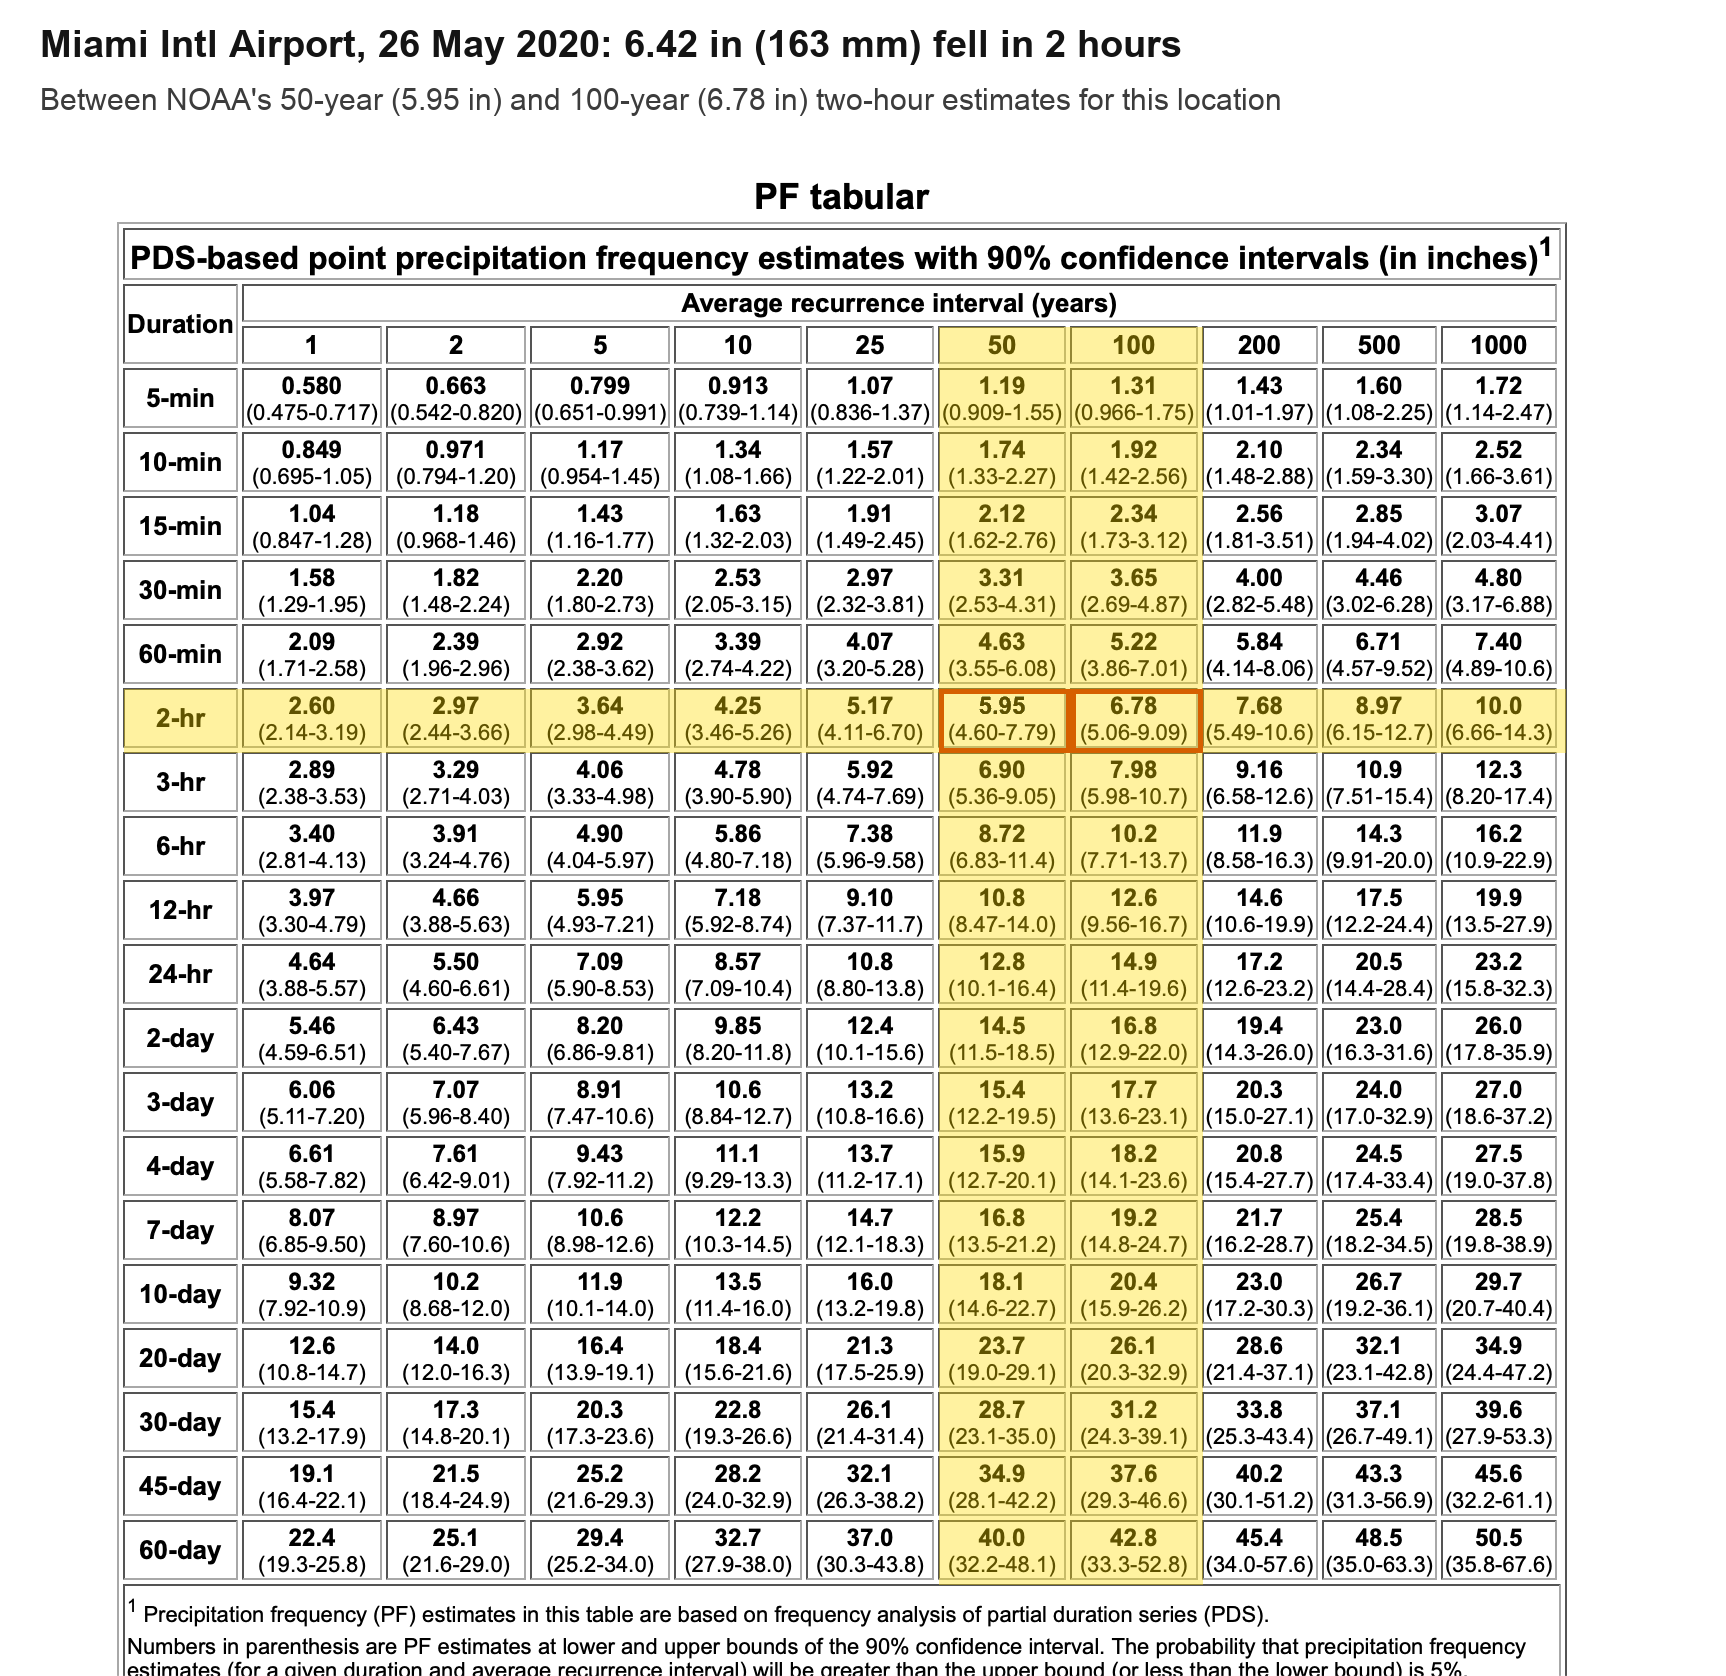

In [239]:
# [orig cell 238 | env: python | status: ok]
ov=Image.new('RGBA',base.size,(0,0,0,0)); d=ImageDraw.Draw(ov)
d.rectangle(row,fill=Y+(95,))
for c in [(939,177,1070,1434),(1071,177,1202,1434)]: d.rectangle(c,fill=Y+(95,))
out=Image.alpha_composite(base,ov); d2=ImageDraw.Draw(out)
for (cx0,cx1) in [(939,1070),(1071,1202)]: d2.rectangle((cx0,539,cx1,602),outline=(214,96,0,255),width=5)
final=Image.new('RGBA',(out.width,out.height+150),(255,255,255,255)); final.paste(strip,(0,0)); final.paste(out,(0,150))
final.convert('RGB').save('atlas14_miami_highlighted.png')